# Setup

In [1]:
import sys

from torchvision.utils import make_grid

sys.path.insert(0, '/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/fast_ai/Part_2/course22p2')
import pickle,gzip,math,os,time,shutil,torch,random,timm,torchvision,io,PIL
import fastcore.all as fc,matplotlib as mpl,numpy as np,matplotlib.pyplot as plt
from collections.abc import Mapping
from pathlib import Path
from operator import attrgetter,itemgetter
from functools import partial
from copy import copy
from contextlib import contextmanager
from rich import progress
import einops

import torchvision.transforms.functional as TF,torch.nn.functional as F
from torchvision import transforms
from torch import tensor,nn,optim
from torch.utils.data import DataLoader,default_collate
from torch.nn import init
from torch.optim import lr_scheduler
from torcheval.metrics import MulticlassAccuracy
from datasets import load_dataset,load_dataset_builder
from fastcore.foundation import L, store_attr

from miniai.datasets import *
from miniai.conv import *
from miniai.learner import *
from miniai.activations import *
from miniai.init import *
from miniai.sgd import *
from miniai.resnet import *

/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


In [2]:
face_url = 'https://external-content.duckduckgo.com/iu/?u=https%3A%2F%2Fi.pinimg.com%2Foriginals%2F27%2Fe0%2Ff4%2F27e0f4c1e3e7e160babfb47482b154d6.jpg&f=1&nofb=1&ipt=071c549cac0a5ee410308285ecc461f92a397bc334ba81bd5b5605091710969e'

vangogh_url = 'https://external-content.duckduckgo.com/iu/?u=https%3A%2F%2Ftse1.mm.bing.net%2Fth%2Fid%2FOIP.hmvF5PpVSz7O6zPzIhMQugHaEo%3Fpid%3DApi&f=1&ipt=e034047db50e9edc664b5432380c1e24fb0c68c7ff3e5b25fd4aecd787398bc3&ipo=images'

In [3]:
# loading the images
def dowload_url(url):
    imgb = fc.urlread(url,decode=False)
    return torchvision.io.decode_image(tensor(list(imgb),dtype=torch.uint8)).float()/255.

shape: torch.Size([3, 1024, 1024])


<Axes: >

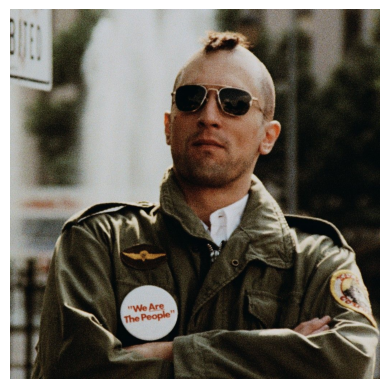

In [4]:
content_im = dowload_url(face_url)
print(f'shape: {content_im.shape}')
show_image(content_im)

In [5]:
from torchvision import transforms
# make the image smaller spacials
trans = transforms.Resize((256,256))
content_im = trans(content_im)

shape: torch.Size([3, 256, 256])


<Axes: >

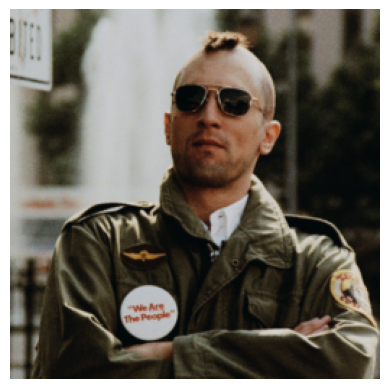

In [6]:
print(f'shape: {content_im.shape}')
show_image(content_im)

In [7]:
content_im.min(),content_im.max() # bet 0 and 1 ?

(tensor(0.0009), tensor(0.8626))

# Style Transfer [NoteBook 1]

# Optimizing images

In [8]:
# make a dummy ds and dl
class LengthDataset():
    def __init__(self,length=1): self.length=length
    def __len__(self): return self.length
    def __getitem__(self, idx): return 0,0

def get_dummy_dls(length=100):
    return DataLoaders(DataLoader(LengthDataset(length), batch_size=1), # Train
                       DataLoader(LengthDataset(1), batch_size=1))    # Valid (length 1)

    CONNECTION BETWEEN THE TWO:
    ─────────────────────────────────────────
    ## __iter__      → you control the pointer manually
                    via yield ✓
    ------
    __iter__ controls EVERYTHING
    python calls it → it yields one by one
    moving pointer forward each time ✓

    class MyData:
        def __iter__(self):
            yield 1
            yield 2
            yield 3
    ------
    EXAMPLE:
    for x in MyData():
        print(x)
    # 1, 2, 3
    -------------------------------------------------
    ## __getitem__   → python controls the pointer
                    calls it with i=0,1,2,3...
                    until it reaches __len__ ✓
    ------
    NO __iter__ defined
    python sees __getitem__ exists
    python automatically does:
    i=0 → calls __getitem__(0) → (0,0)
    i=1 → calls __getitem__(1) → (0,0)
    i=2 → calls __getitem__(2) → (0,0)
    i=3 → i >= __len__() → STOP ✓
    ------
    EXAMPLE:
    class LengthDataset:
        def __len__(self): return 3
        def __getitem__(self, i): return 0,0

    for x in LengthDataset():
        print(x)
    # (0,0), (0,0), (0,0)

    -----------------------------------------------------
    same result
    different mechanism
    __getitem__ is simpler to write
    no yield needed
    no pointer management needed ✓

In [9]:
class TensorModel(nn.Module):
    def __init__(self,t):
        super().__init__()
        self.t = nn.Parameter(t.clone())
    def forward(self,x=0): return  self.t # dummy that just return the parameters

<Axes: >

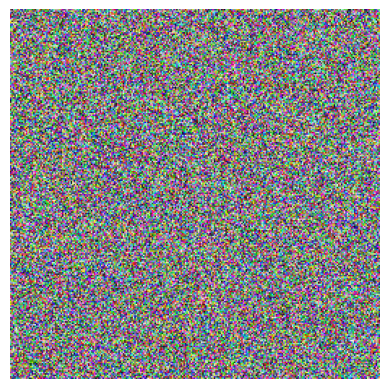

In [10]:
model = TensorModel(torch.rand_like(content_im))
show_image(model())

In [11]:
[p.shape for p in model.parameters()]

[torch.Size([3, 256, 256])]

In [12]:
class ImageOptCB(TrainCB):
    def predict(self,learn): learn.preds = learn.model() # return the params
    def get_loss(self,learn): learn.loss = learn.loss_func(learn.preds)

at loss we are going to make a custom one that have the target (the image) there

In [13]:
# transfer the image to the GPU
content_im = content_im.to(def_device)

In [14]:
loss_fn_mse = partial(F.mse_loss , target=content_im)
model = TensorModel(torch.rand_like(content_im))
cbs = [ImageOptCB(),ProgressCB(), MetricsCB(), DeviceCB()]
learn = Learner(model,get_dummy_dls(),loss_fn_mse,lr=1e-2,cbs=cbs,opt_func=torch.optim.Adam)
learn.fit(1)

loss,epoch,train
0.043,0,train
0.001,0,eval


# Viewing progress

In [15]:
class ImageLogCB(Callback):
    order = ProgressCB.order+1
    def __init__(self,log_every=10): self.images,self.log_every,self.i = [],log_every,0
    def after_batch(self,learn):
        if self.i%self.log_every==0:self.images.append(to_cpu(learn.preds.clip(0,1)))
        self.i+=1
    def after_fit(self,learn): show_images(self.images)

loss,epoch,train
0.029,0,train
0.000,0,eval


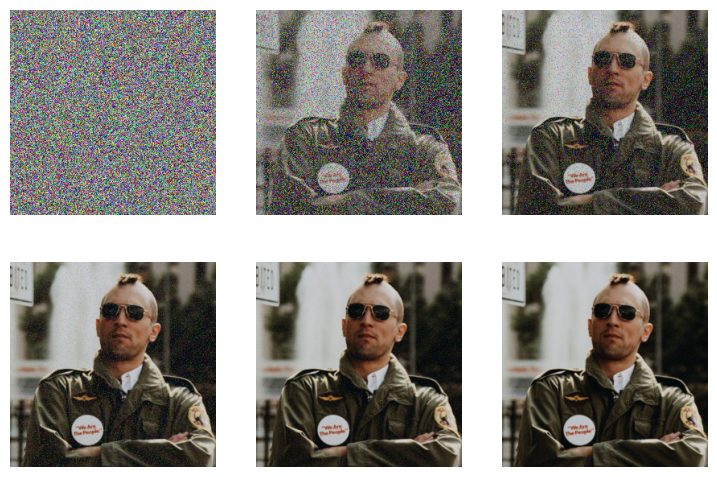

In [16]:
model = TensorModel(torch.rand_like(content_im))
learn = Learner(model, get_dummy_dls(150), loss_fn_mse,
                lr=1e-2, cbs=cbs, opt_func=torch.optim.Adam)
learn.fit(1, cbs=[ImageLogCB(30)])

# Getting features from VGG16

![vgg diag](https://neurohive.io/wp-content/uploads/2018/11/vgg16-1-e1542731207177.png)

we are going to throw away the classification parts because we don't need it here we want the features

In [17]:
print(timm.list_models('*vgg*'))

['repvgg_a0', 'repvgg_a1', 'repvgg_a2', 'repvgg_b0', 'repvgg_b1', 'repvgg_b1g4', 'repvgg_b2', 'repvgg_b2g4', 'repvgg_b3', 'repvgg_b3g4', 'repvgg_d2se', 'vgg11', 'vgg11_bn', 'vgg13', 'vgg13_bn', 'vgg16', 'vgg16_bn', 'vgg19', 'vgg19_bn']


In [18]:
vgg16 = timm.create_model('vgg16', pretrained=True).to(def_device).features

# Normalize the images
 because the VGG was trained on normalized image net with this normalizations

In [19]:
imagenet_mean = tensor([0.485, 0.456, 0.406])
imagenet_std = tensor([0.229, 0.224, 0.225])

In [20]:
imagenet_mean.shape,content_im.shape

(torch.Size([3]), torch.Size([3, 256, 256]))

In [21]:
imagenet_mean[:,None,None].shape # for the broadcasting

torch.Size([3, 1, 1])

In [22]:
def normalize(im):
    imagenet_mean = tensor([0.485, 0.456, 0.406])[:,None,None].to(im.device)
    imagenet_std = tensor([0.229, 0.224, 0.225])[:,None,None].to(im.device)
    return (im - imagenet_mean) / imagenet_std

In [23]:
normalize(content_im).min(), normalize(content_im).max()

(tensor(-2.1139, device='cuda:0'), tensor(1.8733, device='cuda:0'))

In [24]:
normalize(content_im).mean(dim=(1, 2))

tensor([-0.5538, -0.5391, -0.4945], device='cuda:0')

In [25]:
 # torch version
 normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

In [26]:
normalize(content_im).min(), normalize(content_im).max() # same thing

(tensor(-2.1139, device='cuda:0'), tensor(1.8733, device='cuda:0'))

# Getting some representations

## Manual

In [27]:
def calc_features(img,target_layers=(18,25)):
    x = normalize(img)
    feats = []
    for i,layer in enumerate(vgg16[0:max(target_layers)+1]):
        x = layer(x)
        if i in target_layers:
            feats.append(x)
    return feats

In [28]:
feats = calc_features(content_im)
[f.shape for f in feats] # see shape

[torch.Size([512, 32, 32]), torch.Size([512, 16, 16])]

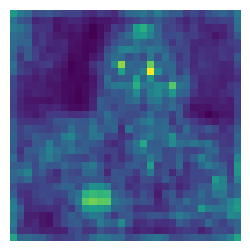

In [29]:
show_images(feats[0].mean(dim=0)[None])

that is something i dont know if it have a meaning, but it is the mean of all channels

## Manual Hooks

In [30]:
feats = []
def calc_feats_hook(collect_list=feats,target_layers=(18,25),model=vgg16):
    hooks = [model[i].register_forward_hook(lambda layer,inp,out:collect_list.append(out)) for i in target_layers]
    return hooks

In [31]:
hooks = calc_feats_hook()

In [32]:
vgg16(content_im)
[l.shape for l in feats]

[torch.Size([512, 32, 32]), torch.Size([512, 16, 16])]

In [33]:
for h in hooks : h.remove()

## Using our hooks

In [34]:
feats=[]
def fn(hook,layer,inp,out):
    feats.append(out)

def calc_feats_hook(collect_list=feats,target_layers=(18,25),model=vgg16):
    hooks =[Hook(model[i],fn) for i in target_layers]
    return hooks # because in the class we made we made Hook.__del__ which will fire if we don't store it

In [35]:
hooks = calc_feats_hook()
vgg16(content_im)
[l.shape for l in feats]

[torch.Size([512, 32, 32]), torch.Size([512, 16, 16])]

    at register_forward_hook(fn) , so for `fn`:
    no partial ->  3 params (just pytorch args) MINI
    with partial ->  4 params (your extra + pytorch args) MAX

In [36]:
for h in hooks : h.remove()

# Optimizing Image with Content Loss

    - Idea : we train the image(noise image)(model_params) to have it's features
    (noise_features) when passed through the model(forzen VGG) to be like the target_features,
     using a loss that compares the noise_features and target_features

## Making on deeper layers + clip() to show images

    target image → VGG → target_features  (fixed, saved once)
    noise image  → VGG → noise_features   (changes every step)
    loss = difference between noise_features and target_features

    then we train the image(noise image) to have it's features(noise_features) when passed
     through the model to be like the target_features

In [37]:
class ContentLossToTarget():
    def __init__(self, target_im, target_layers=(18,25)):
        fc.store_attr()
        with torch.no_grad():
            self.target_feats = calc_features(target_im,target_layers)
    def __call__(self,input_im):
        return sum((f1-f2).pow(2).mean() for f1,f2 in zip(calc_features(input_im,self.target_layers),self.target_feats))

loss,epoch,train
8.061,0,train
2.735,0,eval


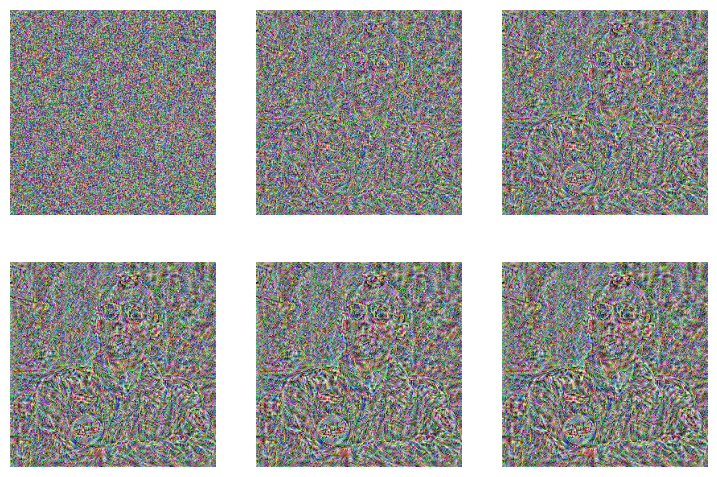

In [38]:
content_loss = ContentLossToTarget(content_im)
model = TensorModel(torch.rand_like(content_im))
learn = Learner(model, get_dummy_dls(150), content_loss,
                lr=1e-2, cbs=cbs, opt_func=torch.optim.Adam)
learn.fit(1, cbs=[ImageLogCB(log_every=30)])

## Making on earlier layers + clip() to show images

loss,epoch,train
2.429,0,train
0.390,0,eval


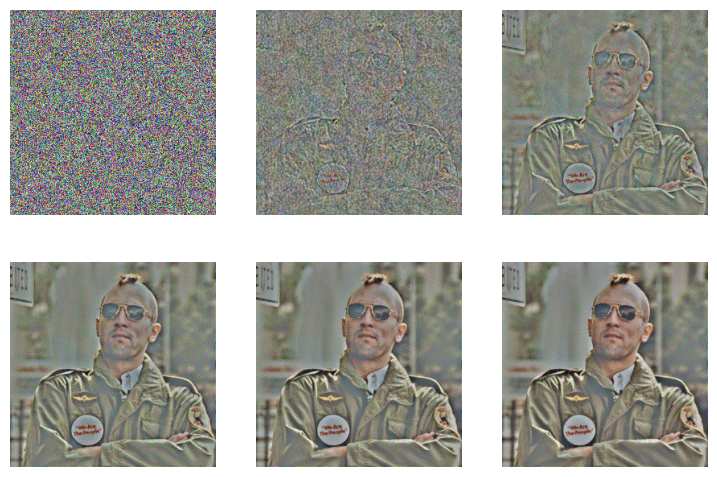

In [39]:
content_loss = ContentLossToTarget(content_im, target_layers=(1, 6))
model = TensorModel(torch.rand_like(content_im))
learn = Learner(model, get_dummy_dls(150), content_loss,
                lr=1e-2, cbs=cbs, opt_func=torch.optim.Adam)
learn.fit(1, cbs=[ImageLogCB(log_every=30)])

## Making on earlier layers + sigmoid() to show images


In [40]:
class ImageLogCB(Callback):
    order = ProgressCB.order+1
    def __init__(self,log_every=10): self.images,self.log_every,self.i = [],log_every,0
    def after_batch(self,learn):
        if self.i%self.log_every==0:self.images.append(to_cpu(torch.sigmoid(learn.preds)))
        self.i+=1
    def after_fit(self,learn): show_images(self.images)

loss,epoch,train
2.419,0,train
0.389,0,eval


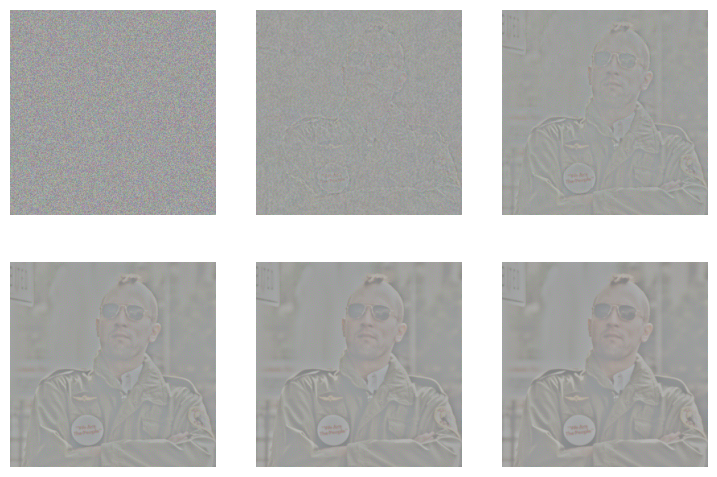

In [41]:
content_loss = ContentLossToTarget(content_im, target_layers=(1, 6))
model = TensorModel(torch.rand_like(content_im))
learn = Learner(model, get_dummy_dls(150), content_loss,
                lr=1e-2, cbs=cbs, opt_func=torch.optim.Adam)
learn.fit(1, cbs=[ImageLogCB(log_every=30)])

That is bad lets redefine the ImageLogCB

In [42]:
class ImageLogCB(Callback):
    order = ProgressCB.order+1
    def __init__(self,log_every=10): self.images,self.log_every,self.i = [],log_every,0
    def after_batch(self,learn):
        if self.i%self.log_every==0:self.images.append(to_cpu(learn.preds.clip(0,1)))
        self.i+=1
    def after_fit(self,learn): show_images(self.images)

## Making a Max Features loss
- just to see what image can activate the layer and a specific feature in there we choose to its maximum

In [43]:
class MaxFeatureLoss():
    def __init__(self,target_layer=26,feature_layer=4):
        self.target_layer,self.feature_layer = (target_layer,) , feature_layer
    def __call__(self,inp):
        return -(calc_features(inp,self.target_layer)[0][self.feature_layer].mean())

- (-ve) in loss is to make the optim try to make the loss lower -> make it more -ve -> make image increase values of layer activations
- `mean()` is just for scale if we make it `sum()` the grads can explode from the huge loss
- (,) in `__init__` -> to make a tuple

loss,epoch,train
-215.746,0,train
-524.002,0,eval
-876.035,1,train
-1236.897,1,eval


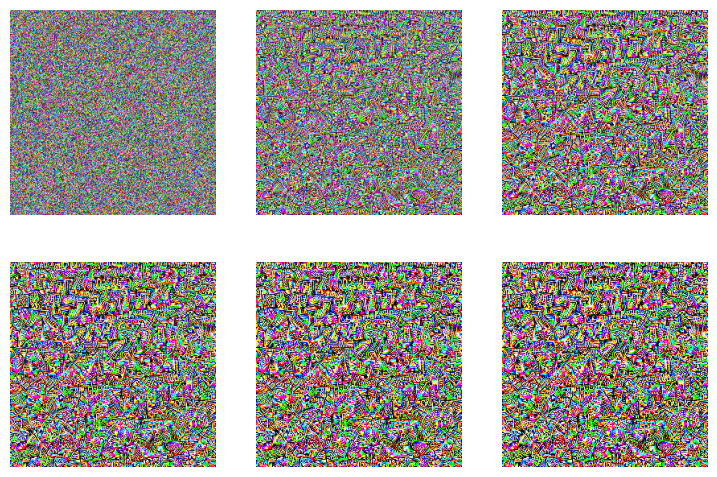

In [44]:
max_feat_loss = MaxFeatureLoss()
model = TensorModel(torch.rand_like(content_im))
learn = Learner(model, get_dummy_dls(150), max_feat_loss,
                lr=1e-2, cbs=cbs, opt_func=torch.optim.Adam)
learn.fit(2, cbs=[ImageLogCB(log_every=60)])

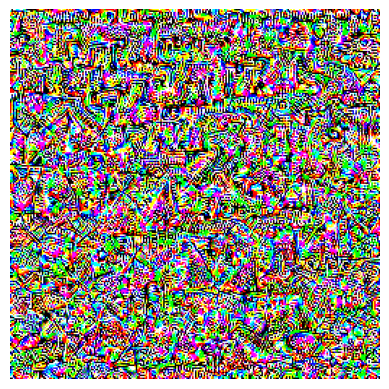

In [45]:
show_image(learn.model().clip(0,1)); # the final image

In [46]:
vgg16

Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU(inplace=True)
  (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (3): ReLU(inplace=True)
  (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (6): ReLU(inplace=True)
  (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (8): ReLU(inplace=True)
  (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (11): ReLU(inplace=True)
  (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (13): ReLU(inplace=True)
  (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (15): ReLU(inplace=True)
  (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (17): Conv2d(256, 512, kernel_si

# Style Loss with Gram Matrix

## Explain

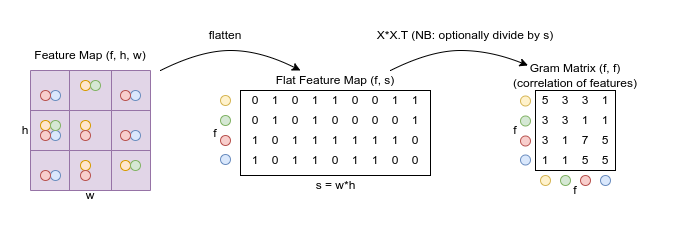

In [47]:
# making an example
t = tensor([[0, 1, 0, 1, 1, 0, 0, 1, 1],
            [0, 1, 0, 1, 0, 0, 0, 0, 1],
            [1, 0, 1, 1, 1, 1, 1, 1, 0],
            [1, 0, 1, 1, 0, 1, 1, 0, 0]])

In [48]:
torch.einsum('bc, fc -> bf',t,t) # b,f are the same thing but we make them diff for the einsum

tensor([[5, 3, 3, 1],
        [3, 3, 1, 1],
        [3, 1, 7, 5],
        [1, 1, 5, 5]])

In [49]:
t@t.T # same thing

tensor([[5, 3, 3, 1],
        [3, 3, 1, 1],
        [3, 1, 7, 5],
        [1, 1, 5, 5]])

## Make the classes and funcitons

torch.Size([3, 256, 256])


<Axes: >

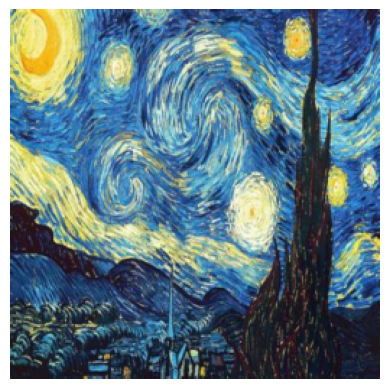

In [50]:
style_im = trans(dowload_url(vangogh_url)).to(def_device)
print(style_im.shape)
show_image(style_im)

In [51]:
def calc_grams(img,target_layers=(1,6,11,18,25)):
    return L(torch.einsum('chw, dhw -> cd', x, x)/(x.shape[-1]*x.shape[-2]) for x in calc_features(img,target_layers))

In [52]:
style_grams = calc_grams(style_im)

In [53]:
[g.shape for g in style_grams]

[torch.Size([64, 64]),
 torch.Size([128, 128]),
 torch.Size([256, 256]),
 torch.Size([512, 512]),
 torch.Size([512, 512])]

In [54]:
style_grams.attrgot('shape') # using fc.L

[torch.Size([64, 64]), torch.Size([128, 128]), torch.Size([256, 256]), torch.Size([512, 512]), torch.Size([512, 512])]

In [55]:
class StyleLossToTarget():
    def __init__(self,target_im, target_layers=(1,6,11,18,25)):
        fc.store_attr()
        with torch.no_grad(): self.target_grams = calc_grams(target_im,target_layers)
    def __call__(self,inp_im):
        return sum((f1-f2).pow(2).mean() for f1,f2 in zip(calc_grams(inp_im,self.target_layers),self.target_grams))

In [56]:
style_loss = StyleLossToTarget(style_im)

In [57]:
style_loss(content_im)

tensor(30.1060, device='cuda:0', grad_fn=<AddBackward0>)

In [58]:
# now make the final combined loss (how much image , how much style)
def combined_loss(x,style_ratio=10):
    return content_loss(x) + style_ratio*style_loss(x)

# Try it

loss,epoch,train
161.780,0,train
28.113,0,eval
26.391,1,train
25.825,1,eval


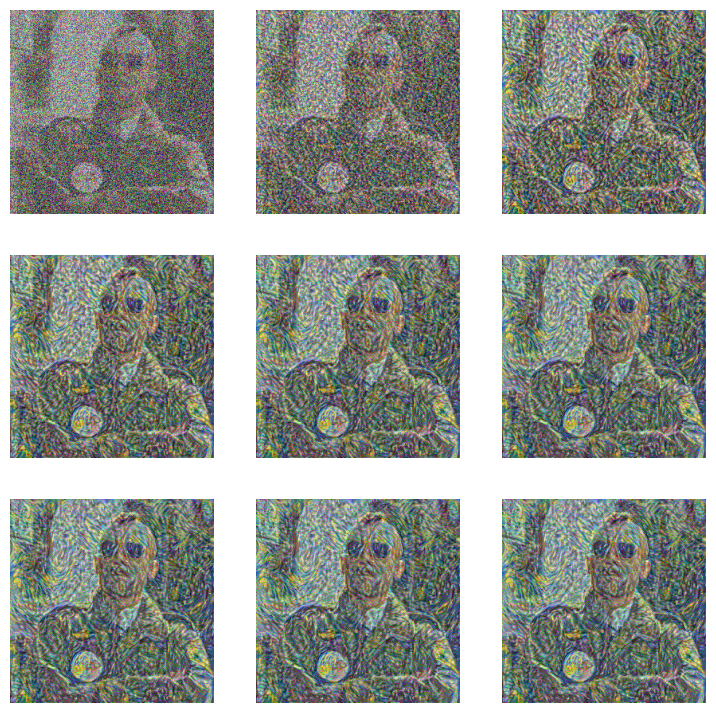

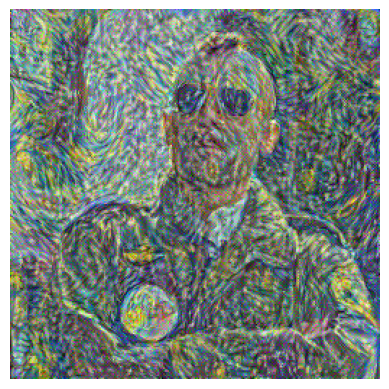

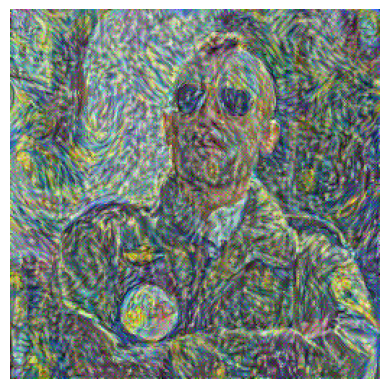

In [59]:
lr = 0.08
epochs = 2
tmax = epochs * 150
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
cbs = [ImageOptCB(),ProgressCB(), MetricsCB(), DeviceCB(),BatchSchedCB(sched)]
model = TensorModel(0.7*torch.rand_like(content_im)+0.3*content_im)
style_loss = StyleLossToTarget(style_im)
content_loss = ContentLossToTarget(content_im)
learn = Learner(model, get_dummy_dls(150), combined_loss, lr=lr, cbs=cbs, opt_func=torch.optim.Adam)
learn.fit(epochs, cbs=[ImageLogCB(30)])

torch.Size([3, 256, 256])


<Axes: >

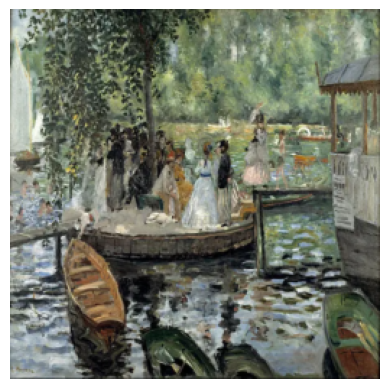

In [60]:
style_im = trans(dowload_url('https://www.artst.org/wp-content/uploads/2022/01/La-Grenouillere-Pierre-Auguste-Renoir.jpg.webp')).to(def_device)
print(style_im.shape)
show_image(style_im)

loss,epoch,train
39.728,0,train
34.863,0,eval
18.700,1,train
15.477,1,eval
15.332,2,train
15.284,2,eval


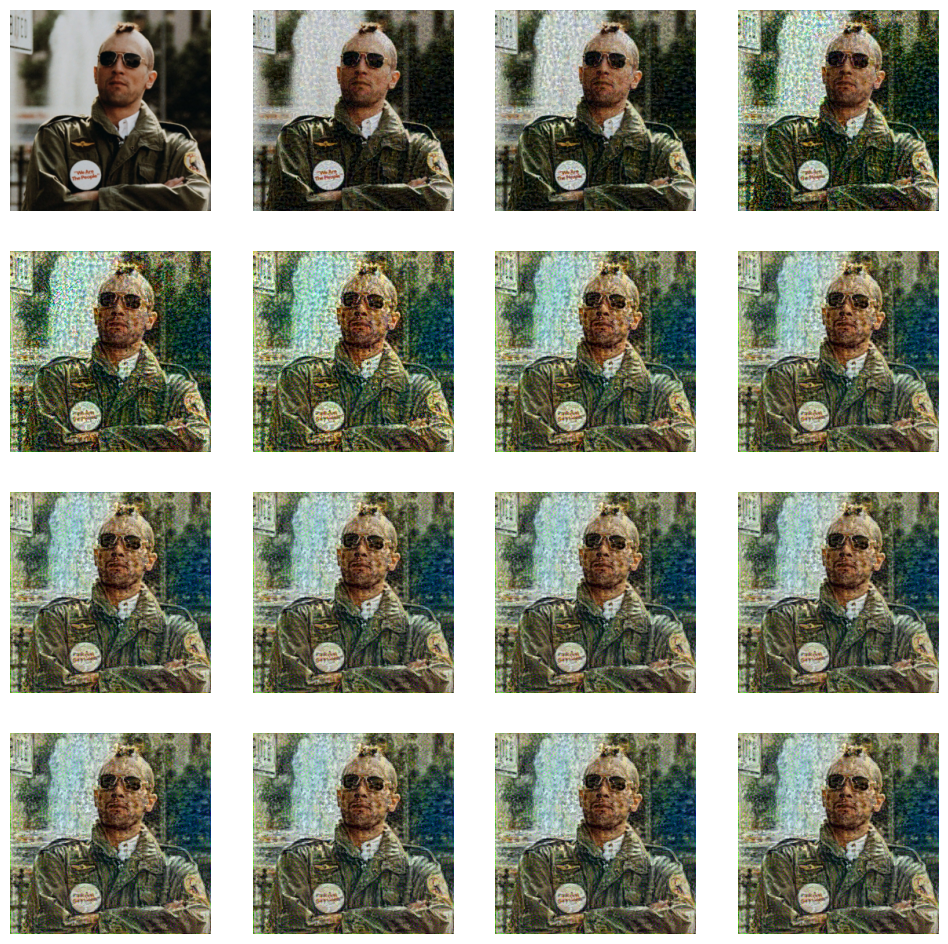

In [61]:
lr = 0.08
epochs = 3
tmax = epochs * 150
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
cbs = [ImageOptCB(),ProgressCB(), MetricsCB(), DeviceCB(),BatchSchedCB(sched)]
model = TensorModel(content_im)
style_loss = StyleLossToTarget(style_im)
content_loss = ContentLossToTarget(content_im)
learn = Learner(model, get_dummy_dls(150), combined_loss, lr=lr, cbs=cbs, opt_func=torch.optim.Adam)
learn.fit(epochs, cbs=[ImageLogCB(30)])

# NCA [NoteBook 2]

# Setup

In [62]:
# just redefine everythhing that we need in same block
vgg16 = timm.create_model('vgg16', pretrained=True).to(def_device).features
normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

def calc_features(imgs, target_layers=[18, 25]):
    x = normalize(imgs)
    feats = []
    for i, layer in enumerate(vgg16[:max(target_layers)+1]):
        x = layer(x)
        if i in target_layers:
            feats.append(x.clone())
    return feats

# Batched version of the previous notebook's gram matrix function
def calc_grams(img, target_layers=[1, 6, 11, 18, 25]):
    return L(torch.einsum('bchw, bdhw -> cd', x, x) / (x.shape[-2]*x.shape[-1])
            for x in calc_features(img, target_layers))

class StyleLossToTarget():
    def __init__(self, target_im, target_layers=[1, 6, 11, 18, 25]):
        fc.store_attr()
        with torch.no_grad(): self.target_grams = calc_grams(target_im[None], target_layers)
    def __call__(self, input_im):
        return sum((f1-f2).pow(2).mean() for f1, f2 in
               zip(calc_grams(input_im, self.target_layers), self.target_grams))

In [63]:
style_im = trans(dowload_url(vangogh_url)).to(def_device)
style_loss = StyleLossToTarget(style_im)
style_loss(torch.rand(1, 3, 256, 256).to(def_device)) # see the loss

tensor(843.1769, device='cuda:0', grad_fn=<AddBackward0>)

# The NCA model

In [64]:
num_channels = 4
hidden_n = 8

In [65]:
def make_grids(n,sz=128): return torch.zeros(n,num_channels,sz,sz).to(def_device)

In [66]:
# Hard-coded filters (they are chosen numbers)
filters = torch.stack([
    tensor([[0.0,0.0,0.0],[0.0,1.0,0.0],[0.0,0.0,0.0]]),
    tensor([[-1.0,0.0,1.0],[-2.0,0.0,2.0],[-1.0,0.0,1.0]]),
    tensor([[-1.0,0.0,1.0],[-2.0,0.0,2.0],[-1.0,0.0,1.0]]).T,
    tensor([[1.0,2.0,1.0],[2.0,-12,2.0],[1.0,2.0,1.0]])]).to(def_device)
filters

tensor([[[  0.,   0.,   0.],
         [  0.,   1.,   0.],
         [  0.,   0.,   0.]],

        [[ -1.,   0.,   1.],
         [ -2.,   0.,   2.],
         [ -1.,   0.,   1.]],

        [[ -1.,  -2.,  -1.],
         [  0.,   0.,   0.],
         [  1.,   2.,   1.]],

        [[  1.,   2.,   1.],
         [  2., -12.,   2.],
         [  1.,   2.,   1.]]], device='cuda:0')

In [67]:
x = make_grids(2)
x.shape

torch.Size([2, 4, 128, 128])

In [68]:
b,ch,h,w = x.shape
b,ch,h,w

(2, 4, 128, 128)

In [69]:
(b*ch,1,h,w)

(8, 1, 128, 128)

In [70]:
y = x.reshape(b*ch,1,h,w)
y.shape

torch.Size([8, 1, 128, 128])

<Axes: >

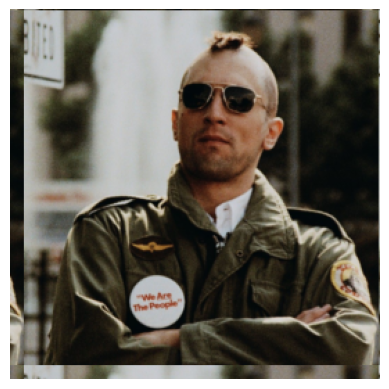

In [91]:
content_im_pad = F.pad(content_im,[10,1,1,10] , 'circular')
show_image(content_im_pad)

In [72]:
y = F.pad(y,[1,1,1,1] , 'circular')
y.shape

torch.Size([8, 1, 130, 130])

In [73]:
filters.shape,filters[:,None].shape

(torch.Size([4, 3, 3]), torch.Size([4, 1, 3, 3]))

In [74]:
y = F.conv2d(y,filters[:,None])
y.shape

torch.Size([8, 4, 128, 128])

In [75]:
y = y.reshape(b,-1,h,w)
y.shape

torch.Size([2, 16, 128, 128])

In [76]:
def perchannel_conv(x,filters):
    b,ch,h,w = x.shape
    y = x.reshape(b*ch,1,h,w)
    y = F.pad(y,[1,1,1,1] , 'circular')
    y = F.conv2d(y,filters[:,None])
    return  y.reshape(b,-1,h,w)

- `y = F.pad(y,[1,1,1,1] , 'circular')` -> add padding from the opposite part for only one pixel so that the edge pixels have the same kind of neighbours
- `y = F.conv2d(y,filters[:,None])` -> kernal -> 3*3 , stride =1
- ` y.reshape(b,-1,h,w)` -> reshapes handles everything, (-1) is like leaving it to torch to adjust it, what is gaurenteed to be in the final shape is the things we made as constants -> b,h,w

    Goal: Make each cell "see" its 3x3 neighbors.

    we have 4 channels per pixel
    we want to apply each filter independently
    to each channel separately

    normal conv2d mixes all channels together,
    not what we want here

    reshape (batch, 4, 128, 128) -> (batch×4, 1, 128, 128)
    treats each channel as its own image

    applies all 4 filters independently per channel
    -> each channel gets its own -> [identity, sobel_x, sobel_y, laplacian]
    -> for each pixel: 4 channels × 4 filters = 16 numbers per pixel ✓


    Circular Padding (1 pixel on all sides)
      → So even edge cells have full neighbors (world wraps around)


    4. Convolution:
       filters.shape        = (4, 3, 3)
       filters[:,None]      = (4, 1, 3, 3)

       F.conv2d(y, filters[:,None])
       → stride=1, kernel_size=3, padding=1

        Final shape: (1, 16, 128, 128)
           → 4 channels × 4 filters = 16 feature maps


    Visualization:

    One Channel (image)  +  4 Filters (3x3)  →  4 new maps per channel
            ↓                           ↓
       3x3 neighborhood         Detects: center, edges, blobs

    Each cell now has 16 numbers describing its local area.
    which are fed to the "brain" (neural net).


In [77]:
x = make_grids(1)
model_inputs = perchannel_conv(x,filters)
model_inputs.shape

torch.Size([1, 16, 128, 128])

In [78]:
brain1 = nn.Sequential(    # linear style
    nn.Linear(num_channels*4, hidden_n,1),
    nn.ReLU(),
    nn.Linear(hidden_n,num_channels,bias=False)).to(def_device)
model_inputs_flat = einops.rearrange(model_inputs, 'b c h w -> (b h w) c') # (bs*128*128, 16)
brain1_preds = brain1(model_inputs_flat)
brain1_preds.shape

torch.Size([16384, 4])

    - w1 bias = starts the signal from nothing because when we start ->
     grid has all pixels as zeros , so k*0 = 0 , so the bias solve this
    - w2 no bias + zero weights = starts as identity
    - grid stays stable and learns gradually ✓

In [79]:
brain1_preds = brain1_preds.reshape(x.shape)
brain1_preds.shape

torch.Size([1, 4, 128, 128])

In [80]:
[p.shape for p in brain1.parameters()]

[torch.Size([8, 16]), torch.Size([8]), torch.Size([4, 8])]

In [81]:
brain2 = nn.Sequential( # conv style
    nn.Conv2d(num_channels*4, hidden_n,1),
    nn.ReLU(),
    nn.Conv2d(hidden_n,num_channels,1,bias=False)).to(def_device)
brain2_preds = brain2(model_inputs).reshape(x.shape)
brain2_preds.shape

torch.Size([1, 4, 128, 128])

In [82]:
[p.shape for p in brain2.parameters()]

[torch.Size([8, 16, 1, 1]), torch.Size([8]), torch.Size([4, 8, 1, 1])]

Putting this into a class, with a few extra features:
- Random update: only update ~50% of the cells
- to_rgb function to scale and show the first 3 channels as an RGB image
- An option to zero out the weights of the second layer. Think: why is this useful?

In [83]:
class SimpleCA(nn.Module):
    def __init__(self,zero_w2=True):
        super().__init__()
        self.w1 = nn.Conv2d(num_channels*4, hidden_n, 1)
        self.relu = nn.ReLU()
        self.w2 = nn.Conv2d(hidden_n, num_channels, 1, bias=False)
        if zero_w2: self.w2.weight.data.zero_()
    def forward(self,x, update_rate=0.5):
        y = perchannel_conv(x,filters) # apply the filters
        y = self.w2(self.relu(self.w1(y))) # pass the result through our 'brain'
        b,c,h,w = y.shape
        update_mask = (torch.rand(b, 1, h, w).to(x.device)+update_rate).floor() # Random update
        return x+y*update_mask

    def to_rgb(self,x):
        return x[...,:3,:,:]+0.5 #  makes colors brighter/visible ✓ [bec. values -> [-1,1]

`if zero_w2: self.w2.weight.data.zero_()` -> to start from zero (.data bypass the autograd to make things smooth)

    torch.rand(b, 1, h, w) -> (1) BROADCAST through all of 4 features

    Example (small grid):text0.12  0.85  0.33
    0.67  0.04  0.91
    0.23  0.55  0.12

    update_rate is usually 0.5
    1.17  0.54  1.41
    0.73  1.05  0.62

    .floor() -> Takes the integer part (rounds down)
    1  0  1
    0  1  0

    Result:  A tensor full of 0s and 1s, Roughly 50% of the values are 1
    (because random + 0.5 → floor)

    why make the random mask?
        if all pixels always update together
        they develop a co-dependency
        pixel A only works when pixel B updated too
        model becomes fragile ✗

        random mask = 50% update each step
        model must work no matter who updated
        each pixel becomes independently robust ✓

        same idea as dropout for neurons
        but here for spatial pixels ✓

    MODEL LEARN TO LEAVE FORMED PATTERNS ALONE:
    x + y × mask

    if pixel already has perfect texture:
    brain sees good neighbors, good state
    predicts y ≈ 0 (no change needed)
    result = x + 0×mask = x (unchanged) ✓


    model learns to predict CHANGES not values
    formed texture → predict ~0 (leave alone)
    empty/damaged → predict useful update ✓


# Training

In [84]:
class LengthDataset():
    def __init__(self, length=1): self.length=length
    def __len__(self): return self.length
    def __getitem__(self, idx): return 0,0

def get_dummy_dls(length=100):
    return DataLoaders(DataLoader(LengthDataset(length), batch_size=1),
                       DataLoader(LengthDataset(1), batch_size=1))

In [85]:
class NCAProgressCB(ProgressCB):
    def after_batch(self, learn):
        learn.dl.comment = f'{learn.loss:.3f}'
        if not (hasattr(learn, 'metrics') and learn.training): return
        self.losses.append(learn.loss.item())
        mbar = self.mbar
        if not hasattr(mbar, 'graph_fig'):
            mbar.graph_fig, mbar.graph_axs = plt.subplots(1, 2, figsize=(12, 3.5))
            mbar.graph_out = display(mbar.graph_fig, display_id=True)

        # Update preview image every 64 iters
        if (len(self.losses))%64 != 10: return

        # Plot losses:
        mbar.graph_axs[0].clear()
        mbar.graph_axs[0].plot(self.losses, '.', alpha=0.3)
        mbar.graph_axs[0].set_yscale('log')
        mbar.graph_axs[0].set_ylim(tensor(self.losses).min(), self.losses[0])

        # Show preview images:
        rgb = learn.model.to_rgb(learn.preds.detach()).clip(0, 1)
        show_image(torchvision.utils.make_grid(rgb), ax=mbar.graph_axs[1])

        # Update graph
        mbar.graph_out.update(mbar.graph_fig)

In [86]:
class NCACB(TrainCB):
    order = DeviceCB.order+1
    def __init__(self, ca, style_img_tensor, style_loss_scale=0.1, size=256,
                 step_n_min=32, step_n_max=96, batch_size=2):
        fc.store_attr()
        with torch.no_grad(): self.pool = make_grids(256,sz=size)# grids pool

    def predict(self,learn):
        # Pick some random samples from the pool
        batch_idx = torch.randint(0, len(self.pool), (self.batch_size,))
        x = self.pool[batch_idx]
        # ocasionally zero out samples
        if torch.randint(8,(1,)) < 1: # means roughly 1/8 chance
            x[:1] = make_grids(1,self.size)
        # apply model for a number of times
        for _ in range(torch.randint(self.step_n_min, self.step_n_max, (1,))):
            x = learn.model(x)
        # Update pool
        with torch.no_grad(): self.pool[batch_idx] = x
        # and store preds
        learn.preds = x
        # def get_loss
    def get_loss(self, learn):
        style_loss = learn.loss_func(learn.model.to_rgb(self.learn.preds))
        overflow_loss = (learn.preds-learn.preds.clamp(-1.0, 1.0)).abs().sum()
        learn.loss = overflow_loss + style_loss*self.style_loss_scale
    # backward + (gradient normalization)
    def backward(self, learn):
        learn.loss.backward()
        for p in learn.model.parameters():
            p.grad /= (p.grad.norm()+1e-8)
    #
    def before_fit(self, learn): self.learn=learn

- `(1,)` -> shape of output tensor -> give me ONE random number

    pool = memory of different growth stages
    trains model to work from any starting point
    and maintain texture at any step
    naturally leads to self-healing behavior ✓

    we are NOT optimizing pixels this time
    we are optimizing the BRAIN WEIGHTS

    brain weights = the rules that tell
    each pixel how to update itself

    goal: find weights that make ANY grid
          grow into spiderweb texture
          regardless of starting point ✓

    loss = style loss (gram matrix vs spiderweb)
    if brain makes bad texture → high loss
    if brain makes good texture → low loss
    weights update to make loss lower ✓

    at -> for _ in range(100):
             x = learn.model(x)  ← same weights used each time

    gradient flows back through all 100 steps
    very expensive computationally ✓
    but necessary to learn long-range behavior ✓

    p.grad /= (p.grad.norm() + 1e-8)

    grad.norm() = overall size of gradient
    dividing = keep direction, remove size

    100 steps of backprop can create
    wildly different gradient sizes
    sometimes huge → weights explode ✗
    sometimes tiny → weights barely move ✗

    normalization -> always same size step ✓
    +1e-8: prevents division by zero

In [87]:
model = SimpleCA().to(def_device)
cbs = [NCACB(model, style_im), NCAProgressCB(), MetricsCB()]
style_loss = StyleLossToTarget(style_im)

learn = Learner(model, get_dummy_dls(1200), style_loss, lr=1e-3, cbs=cbs, opt_func=torch.optim.Adam)

loss,epoch,train
162.726,0,train
1.392,0,eval


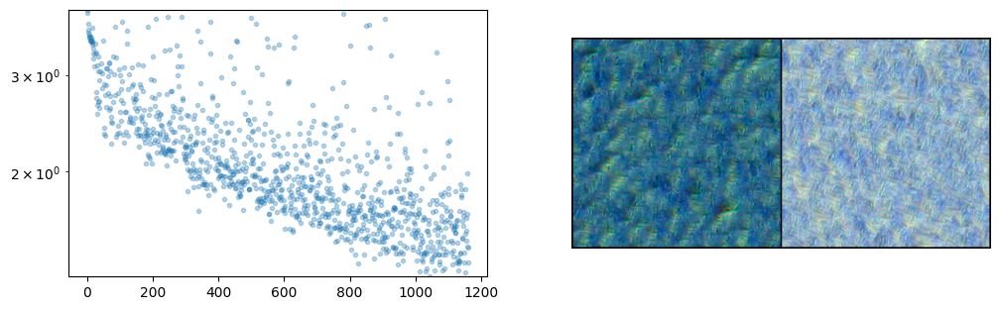

In [88]:
learn.fit(1)

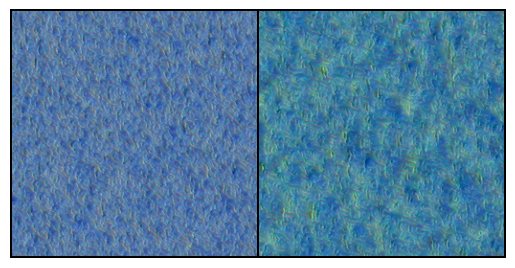

In [89]:
# Check out the final batch:
rgb = model.to_rgb(learn.preds.detach())
rgb = torchvision.utils.make_grid(rgb)
show_image(rgb.clip(0, 1));

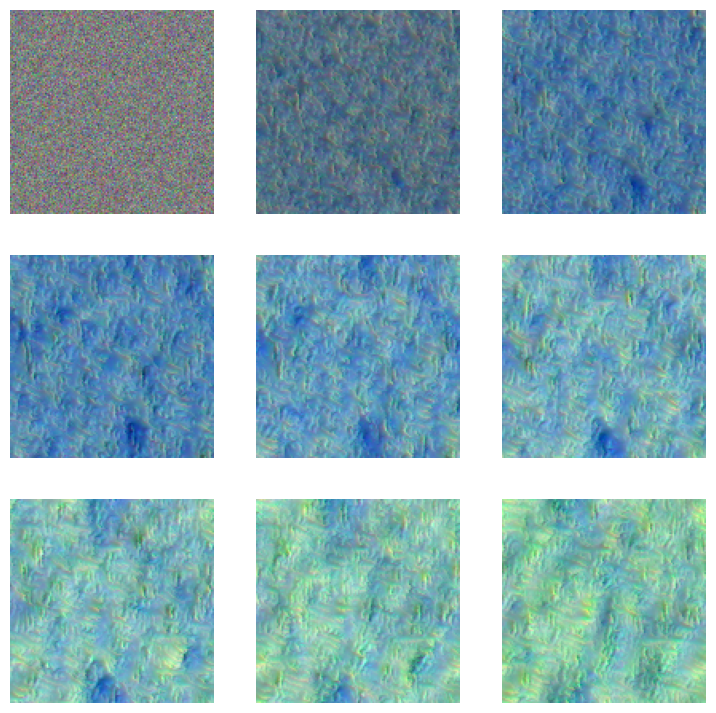

In [94]:
# Apply a number of times to a random initial starting grid:
images = []
x = torch.randn(1, num_channels, 128, 128).to(def_device) * 0.1
for i in range(900):
    x = model(x)
    if i%100==0: images.append(model.to_rgb(x)[0].clip(0, 1))
show_images(images)

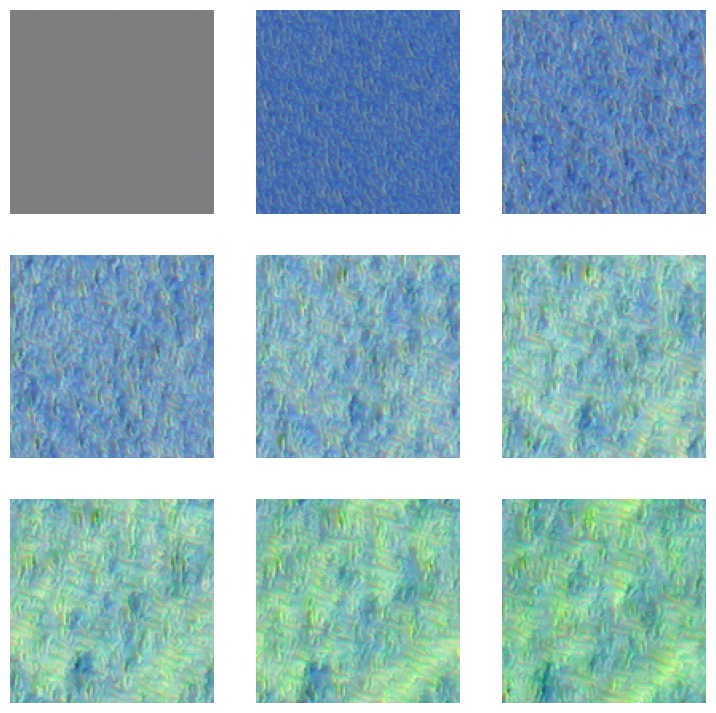

In [95]:
# Apply a number of times to a random initial starting grid:
images = []
x = torch.zeros(1, num_channels, 128, 128).to(def_device)
for i in range(900):
    x = model(x)
    if i%100==0: images.append(model.to_rgb(x)[0].clip(0, 1))
show_images(images)